# Pre-class: Morning Briefing — Session Data + Baseline
**⏱ This pre-class notebook takes approximately 20 minutes (matching the pre-class schedule).**

---

## Scenario: Morning briefing — Marcus's Sequential-Behaviour Question

End of L06 Marcus said:

> *"If we collected DETAILED CUSTOMER BEHAVIOUR DATA — every click, every page view, every cart event — could you predict whether they'd complete checkout WHILE THEY'RE SHOPPING?"*

NorthStar's data team has now logged 8,000 customer sessions. Each session has 9 behavioural features (pages viewed, time on site, items added, etc.) and a binary label (`completed`: did they finish checkout?).

Today Sarah will train three models on this data and compare:
1. **Logistic regression** (L03 baseline)
2. **Gradient boosting** (L04 toolkit)
3. **Neural network** (today's new tool — MLP in PyTorch)

The point isn't to "win". Conventional wisdom says gradient boosting should win on tabular data this size — keep that expectation in mind, because the in-class results will put it to the test. The point is to LEARN NEURAL NETWORKS as a foundation for L08 (images), L09 (text), L10 (transformers).

**By the end of this notebook you will be able to:**
- Describe the session-data structure
- Spot which features are most predictive (visually)
- See the L03 logistic-regression baseline accuracy + AUC

In [1]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 4.5)

print("✅ Libraries loaded")

✅ Libraries loaded


## Load the data

The target column **`completed`** is our label: `1` = the customer finished checkout (made a purchase) during that session, `0` = they left without buying. Every other column (except `session_id`) is a behavioural feature we'll use to predict it.

In [2]:
# Read the session log into a DataFrame (a table of rows × columns).
df = pd.read_csv("data/northstar_sessions.csv")
print(f"Loaded: {len(df):,} sessions × {df.shape[1]} columns")   # rows = sessions, columns = features + id + label
# .mean() of a 0/1 column = the fraction that are 1 → here, the share of sessions that completed checkout.
print(f"Completion rate: {df['completed'].mean():.1%}")
print()
df.head()   # show the first 5 rows so we can eyeball what each column looks like

Loaded: 8,000 sessions × 11 columns
Completion rate: 42.8%



,session_id,pages_viewed,time_on_site_min,items_added,cart_total_gbp,used_discount_code,is_returning,device_mobile,hour_of_day,prev_orders,completed
0,900000,8,1.0,1,53.75,0,1,1,10,1,1
1,900001,8,1.1,0,0.00,0,0,1,11,0,0
2,900002,9,4.7,0,0.00,0,0,0,8,0,0
3,900003,7,2.4,1,29.70,0,1,1,20,3,1
4,900004,6,13.9,2,86.46,1,0,0,8,0,1


## Step 1 — Quick EDA

In [3]:
# .describe() prints count/mean/std/min/quartiles/max for every numeric column —
# a fast way to sanity-check ranges and spot anything odd. Drop the id column (it's just a label, not a feature).
print("Feature summary:")
print(df.drop(columns=["session_id"]).describe().round(2))

Feature summary:
       pages_viewed  time_on_site_min  items_added  cart_total_gbp  \
count       8000.00           8000.00      8000.00         8000.00   
mean           6.00              3.99         1.41           49.07   
std            2.48              4.01         1.18           46.28   
min            1.00              0.10         0.00            0.00   
25%            4.00              1.20         1.00            7.23   
50%            6.00              2.80         1.00           39.68   
75%            8.00              5.50         2.00           73.99   
max           19.00             41.10         7.00          348.89   

       used_discount_code  is_returning  device_mobile  hour_of_day  \
count             8000.00       8000.00        8000.00      8000.00   
mean                 0.18          0.54           0.66        11.45   
std                  0.39          0.50           0.47         6.89   
min                  0.00          0.00           0.00         0.00 

## Step 2 — Which features look most predictive?

Plot a bar chart of mean target by feature value (for binary features) and compare distributions by target (for numeric features).

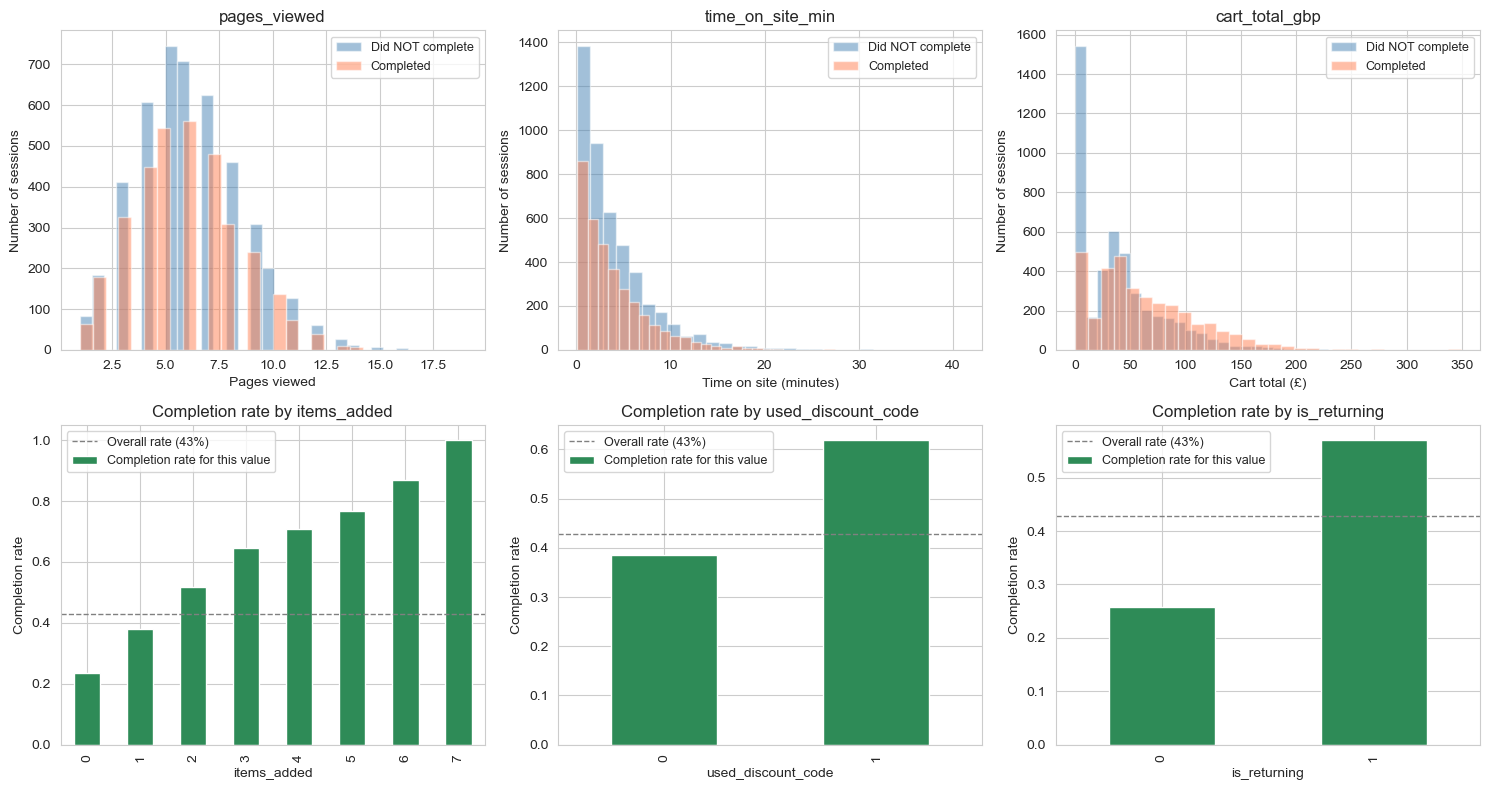

In [4]:
# Goal: eyeball which features separate "completed" from "not completed".
# A 2×3 grid of small charts: top row = numeric features, bottom row = binary/count features.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# --- Numeric features: overlay two histograms (completed vs not) to compare their shapes ---
# If the orange and blue humps sit in different places, that feature helps tell the classes apart.
x_labels = {"pages_viewed": "Pages viewed", "time_on_site_min": "Time on site (minutes)", "cart_total_gbp": "Cart total (£)"}
for ax, col in zip(axes.flat[:3], ["pages_viewed", "time_on_site_min", "cart_total_gbp"]):
    df[df["completed"] == 0][col].hist(bins=30, alpha=0.5, ax=ax, color="steelblue", label="Did NOT complete")
    df[df["completed"] == 1][col].hist(bins=30, alpha=0.5, ax=ax, color="coral", label="Completed")
    ax.set_title(col)
    ax.set_xlabel(x_labels[col]); ax.set_ylabel("Number of sessions")   # histogram height = how many sessions fall in each bin
    ax.legend(fontsize=9)

# --- Binary / count features: bar of completion RATE per value ---
# groupby(col)["completed"].mean() = "of the sessions with this value, what fraction completed?"
for ax, col in zip(axes.flat[3:], ["items_added", "used_discount_code", "is_returning"]):
    rate_by_val = df.groupby(col)["completed"].mean()
    rate_by_val.plot(kind="bar", ax=ax, color="seagreen", edgecolor="white", label="Completion rate for this value")
    ax.set_title(f"Completion rate by {col}")
    ax.set_xlabel(col); ax.set_ylabel("Completion rate")
    # dashed line = the overall completion rate, so we can see which bars beat the average
    ax.axhline(df["completed"].mean(), color="gray", linestyle="--", linewidth=1, label=f"Overall rate ({df['completed'].mean():.0%})")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### 💡 What you should notice

- **`items_added`** is dominant — sessions with items in the cart complete much more often than sessions with empty carts.
- **`is_returning`** helps — returning customers convert more (familiarity, trust).
- **`used_discount_code`** is a strong positive signal — people who apply discounts are committed to buying.
- **`time_on_site` and `pages_viewed`** show overlapping distributions — they correlate with completion but not as cleanly.

## Step 3 — Logistic regression baseline (the L03 bar to beat)

In [5]:
# Split the table into the LABEL (what we predict) and the FEATURES (what we predict from).
y = df["completed"]                                  # 1 = completed checkout, 0 = did not
X = df.drop(columns=["session_id", "completed"])     # drop the id and the answer; keep the 9 behaviour columns

# Hold out 20% as a TEST set; stratify keeps the same completed/not ratio in train and test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42,
)

# Every column here is already numeric (binary flags don't strictly need scaling, but it's harmless).
numeric_features = X.columns.tolist()

# A preprocessor that, for the numeric columns: fills any missing values with the median, then rescales
# to mean 0 / std 1 (logistic regression behaves better when features are on a similar scale).
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("scl", StandardScaler())]), numeric_features),
])

# A Pipeline chains the preprocessing and the model so .fit() runs both in the right order
# AND learns the scaling on train only — no leakage of test info.
lr_pipeline = Pipeline([
    ("prep",  preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

lr_pipeline.fit(X_train, y_train)                    # learn the scaler + fit the model in one call
y_pred_lr = lr_pipeline.predict(X_test)              # hard yes/no predictions
y_proba_lr = lr_pipeline.predict_proba(X_test)[:, 1] # probability of class "1" (used for AUC)

print(f"=== Logistic Regression baseline ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.3f}")   # fraction of correct yes/no calls
print(f"AUC:      {roc_auc_score(y_test, y_proba_lr):.3f}")   # ranking quality (1.0 = perfect, 0.5 = coin flip)
print()
# precision/recall/F1 broken down per class — shows where the model is strong vs weak
print(classification_report(y_test, y_pred_lr, target_names=["did NOT complete", "completed"]))

=== Logistic Regression baseline ===
Accuracy: 0.703
AUC:      0.761

                  precision    recall  f1-score   support

did NOT complete       0.72      0.79      0.75       916
       completed       0.67      0.59      0.63       684

        accuracy                           0.70      1600
       macro avg       0.70      0.69      0.69      1600
    weighted avg       0.70      0.70      0.70      1600



### 💡 What this tells us

- **Baseline accuracy ~70%** — better than the 57% **no-skill majority class**. (The "no-skill majority" is the score you'd get by ignoring the features and always guessing the most common answer. Here 57% of sessions did NOT complete, so always predicting "did not complete" would be right 57% of the time. Any useful model must beat that.)
- **AUC ~0.76** — the model can rank sessions but isn't perfectly separating them. (**AUC** = Area Under the ROC Curve; **ROC** = Receiver Operating Characteristic. Read it as: pick one completed session and one non-completed session at random — AUC is the probability the model gives the completed one a higher score. 1.0 = perfect ranking, 0.5 = no better than a coin flip.)
- **Logistic regression is LINEAR** — it can only learn linear combinations of features. If there are NONLINEAR interactions (e.g., "high cart total AND new visitor → drop"), it'll miss them.

This is the bar. In class we'll train a Multi-Layer Perceptron and see if its non-linearity helps.

### 📈 Seeing the AUC — the ROC curve

"AUC ~0.76" is just a number. Let's **draw** it, so you can see what it measures.

The model doesn't really output yes/no — it outputs a **score** (a probability between 0 and 1) for every session. To get a yes/no we pick a **cut-off**: "predict *completed* if the score is above the cut-off". The default cut-off is 0.5, but nothing forces that choice.

The chart on the left — the **ROC curve** (**R**eceiver **O**perating **C**haracteristic) — shows what happens at *every possible* cut-off at once. *(The odd name comes from WWII radar: engineers used this chart to judge how well a radar receiver told real planes apart from noise.)*
- **Up the side (y-axis):** of the sessions that really completed, what share did we catch? (*catch rate*, a.k.a. recall / true-positive rate)
- **Along the bottom (x-axis):** of the sessions that did NOT complete, what share did we wrongly flag as completing? (*false-alarm rate*, a.k.a. false-positive rate)

**AUC is the shaded area under that curve.** The chart on the right shows *why* the area isn't 1.0: the scores of the two groups overlap.

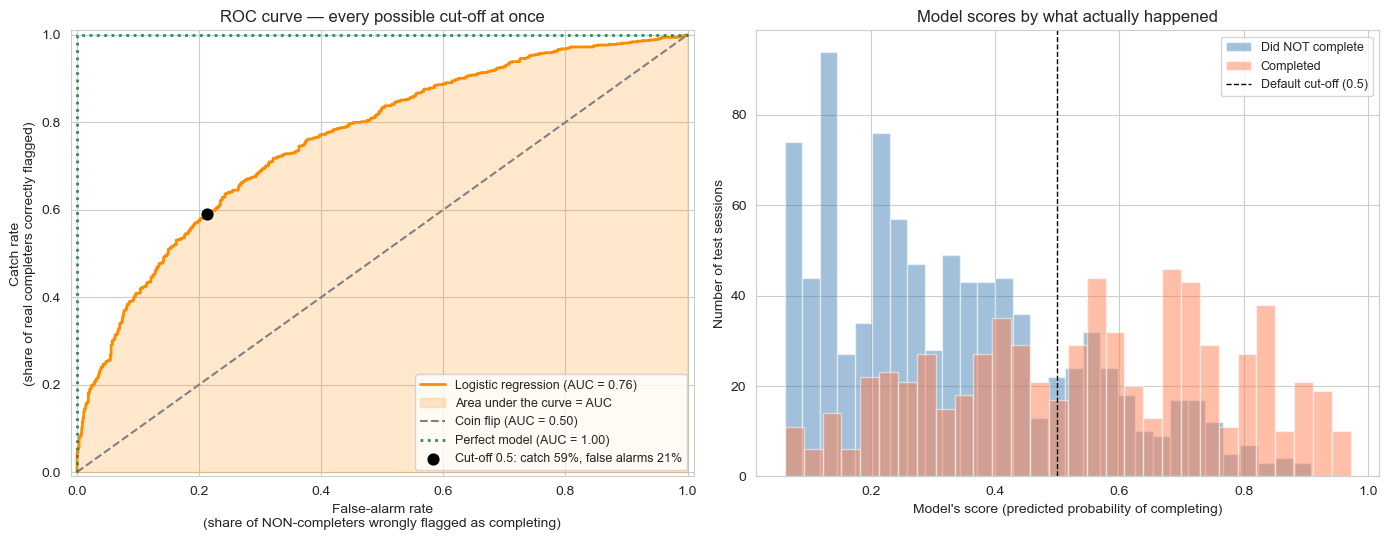

AUC from the curve:                                   0.761
Random completer scored above random non-completer:   0.760 of the time


In [6]:
from sklearn.metrics import roc_curve

# Every possible cut-off → one (false-alarm rate, catch rate) point. Joining them gives the ROC curve.
fpr, tpr, thresholds = roc_curve(y_test, y_proba_lr)
auc = roc_auc_score(y_test, y_proba_lr)

# Where does the default 0.5 cut-off sit on the curve?
at_half = (y_proba_lr >= 0.5)
tpr_half = at_half[y_test.values == 1].mean()    # share of real completers we flag
fpr_half = at_half[y_test.values == 0].mean()    # share of non-completers we wrongly flag

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Left: the ROC curve, with the AUC shaded ---
ax = axes[0]
ax.plot(fpr, tpr, color="darkorange", linewidth=2, label=f"Logistic regression (AUC = {auc:.2f})")
ax.fill_between(fpr, tpr, alpha=0.2, color="darkorange", label="Area under the curve = AUC")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Coin flip (AUC = 0.50)")
ax.plot([0, 0, 1], [0, 1, 1], ":", color="seagreen", linewidth=2, label="Perfect model (AUC = 1.00)")
ax.scatter([fpr_half], [tpr_half], color="black", zorder=5, s=60,
           label=f"Cut-off 0.5: catch {tpr_half:.0%}, false alarms {fpr_half:.0%}")
ax.set_xlabel("False-alarm rate\n(share of NON-completers wrongly flagged as completing)")
ax.set_ylabel("Catch rate\n(share of real completers correctly flagged)")
ax.set_title("ROC curve — every possible cut-off at once")
ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01)
ax.legend(loc="lower right", fontsize=9)

# --- Right: the model's scores for the two groups ---
# AUC < 1 because these two humps overlap: some non-completers score higher than some completers.
ax = axes[1]
ax.hist(y_proba_lr[y_test.values == 0], bins=30, alpha=0.5, color="steelblue", label="Did NOT complete")
ax.hist(y_proba_lr[y_test.values == 1], bins=30, alpha=0.5, color="coral", label="Completed")
ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Default cut-off (0.5)")
ax.set_xlabel("Model's score (predicted probability of completing)")
ax.set_ylabel("Number of test sessions")
ax.set_title("Model scores by what actually happened")
ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

# The plain-English meaning of AUC, checked directly:
# pick a random completer and a random non-completer — how often does the completer get the higher score?
rng = np.random.default_rng(42)
pos = rng.choice(y_proba_lr[y_test.values == 1], 100_000)
neg = rng.choice(y_proba_lr[y_test.values == 0], 100_000)
print(f"AUC from the curve:                                   {auc:.3f}")
print(f"Random completer scored above random non-completer:   {(pos > neg).mean():.3f} of the time")


### 💡 How to read the chart — in plain English

**The one-sentence meaning of AUC:** pick one customer who completed checkout and one who didn't, at random. AUC is **how often the model gives the completer the higher score**. Ours is ~0.76, so it ranks the pair correctly about **3 times out of 4**. The two numbers printed under the chart show this directly.

**Reading the left chart (ROC curve):**
- **The grey diagonal is a coin flip.** A model that guesses randomly catches more completers only by raising false alarms at the same rate. Area = 0.5.
- **The green corner line is a perfect model.** It catches 100% of completers with 0% false alarms. Area = 1.0.
- **Our orange curve sits in between.** The more it bulges toward the **top-left corner**, the better the model is at ranking. The shaded area is the AUC.
- **The black dot is the default 0.5 cut-off.** At that cut-off we catch about 6 in 10 completers and wrongly flag about 2 in 10 non-completers. These match the `recall` numbers in the report above (0.59 for *completed*, and 1 − 0.79 for *did NOT complete*).
- **Moving along the curve = changing the cut-off.** Lower the cut-off and you move up and to the right: you catch more completers but raise more false alarms. AUC sums up the whole curve, so it **doesn't depend on which cut-off you pick**. That's why we compare models with it.

> 🤔 **Why don't the catch rate and false-alarm rate add up to 100%?** They're percentages of **different groups**. The catch rate is out of the real *completers* (684 people); the false-alarm rate is out of the real *non-completers* (916 people). At the 0.5 cut-off we flag ~404 of the 684 completers (59%) and ~192 of the 916 non-completers (21%). Two separate pies, so adding them together means nothing. The pairs that do add up to 100% stay within one group: catch 59% + miss 41%, and false alarm 21% + correctly ignored 79%.
>
> **Why do both go up together?** The cut-off is one dial for everyone. Lower it and you flag more people, and some of the newly flagged come from *each* group, because their scores overlap (see the right chart). It's like turning up an airport metal detector: it catches more real weapons, but also beeps at more belt buckles. A good model gains lots of catches before the false alarms pile up, so its curve shoots up early.

**Reading the right chart (scores):**
- If the model were perfect, all the orange (completed) bars would sit to the right of all the blue ones, with no overlap.
- Ours overlap in the middle. Every time a blue session scores higher than an orange one, the model has ranked that pair wrongly. **That overlap is the missing area (1 − AUC).**

**Rule of thumb:** 0.5 = useless · 0.7–0.8 = decent · 0.8–0.9 = strong · above 0.9 = excellent (or check for leakage!). Our ~0.76 is decent. That's the bar the neural network must beat in class.

### 🔗 How ROC / AUC connect to precision, recall and F1

The classification report above and the ROC chart are describing the same model. Here's how they fit together:

| Measure | What it asks (for "completed") | Our value | Where it is on the ROC chart |
|---|---|---|---|
| **Recall** | Of the people who really completed, how many did we catch? | 0.59 | **Yes**: it's the height of the black dot (catch rate) |
| **Precision** | Of the people we *said* would complete, how many really did? | 0.67 | **No**: the ROC chart doesn't show it |
| **F1** | One number that balances precision and recall | 0.63 | **No**: it's built from precision, which isn't on the chart |
| **AUC** | How well does the model *rank* completers above non-completers? | 0.76 | **Yes**: it's the shaded area |

**The big difference: one cut-off vs. all cut-offs.**
- Precision, recall and F1 are measured at **one cut-off** (here 0.5). Change the cut-off and all three change. The classification report is a snapshot of the single black dot.
- The ROC curve shows **every cut-off at once**, and AUC sums the whole curve into one number. That's why AUC stays the same whatever cut-off you choose.

**When to use which:**
- **Comparing models?** Use **AUC**. It doesn't depend on picking a cut-off.
- **Deciding how to act on the predictions?** Use **precision / recall / F1** at the cut-off you'll actually use. For example: "if we send a discount to everyone scoring above 0.5, how many will really buy (precision), and how many buyers will we reach (recall)?"


## ✅ Section Summary

| What we did | Result |
|---|---|
| **Loaded session data** | 8,000 sessions × 9 features |
| **Saw the EDA** | items_added is the strongest signal; is_returning + discount also help |
| **Trained L03 logistic regression** | Accuracy ~70%, AUC ~0.76 |

**The bar to beat in class:** can a neural network beat AUC ~0.76? (Spoiler for class: all the models end up tied within ~0.015 AUC — the real prize is learning the PyTorch training loop.)

**Bring to class:**
1. The baseline accuracy + AUC numbers
2. Two features you think will be most important to the neural network
3. One question about how a network "learns" what the features mean

---
**In class → Open `02_perceptron_to_mlp.ipynb` first.**